# Lab 7: Binary Classification using Logistic Regression

### Objectives:
 1. Load and preprocess the loan approval dataset.
 2. Map categorical variables into numerical formats.
 3. Apply StandardScaler to financial features to optimize the Sigmoid curve calculation.
 4. Train a Logistic Regression model to predict binary loan status.
 5. Evaluate the model using Accuracy, Precision, Recall, and a Confusion Matrix.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [16]:
df = pd.read_csv("/content/loan_approval_dataset.csv")
df.columns = df.columns.str.strip()

In [17]:
le = LabelEncoder()
df['education'] = le.fit_transform(df['education'])
df['self_employed'] = le.fit_transform(df['self_employed'])
df['loan_status'] = le.fit_transform(df['loan_status'])

In [18]:
X = df[['income_annum', 'loan_amount', 'loan_term', 'cibil_score']]
y = df['loan_status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)

print("Logistic Regression Performance:")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")

Logistic Regression Performance:
Accuracy:  0.9052
Precision: 0.8762
Recall:    0.8679


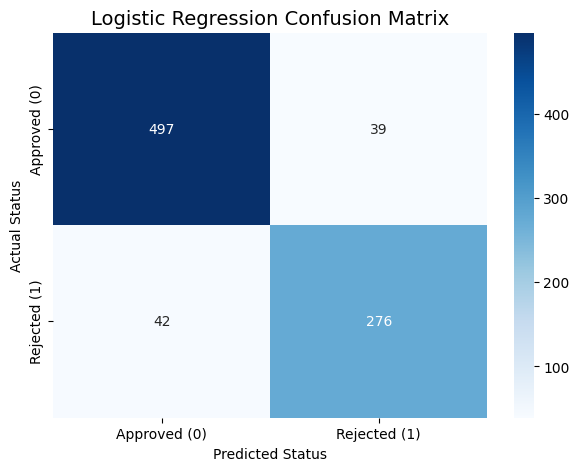

In [20]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Approved (0)', 'Rejected (1)'],
            yticklabels=['Approved (0)', 'Rejected (1)'])
plt.title('Logistic Regression Confusion Matrix', fontsize=14)
plt.ylabel('Actual Status')
plt.xlabel('Predicted Status')
plt.show()